In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[2] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

# Clear the cache if needed
# adapter.clear_cache()

In [2]:

START = "2026-04-30"
END = "2026-05-30"
TICKERS = "ALL_SYMBOLS"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = adapter.scan_data(
    tickers=TICKERS,
    start_date=START,
    end_date=END,
    dataset=DATASET,
    schema="imbalance"
)
df_imbalance = df_imbalance.with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"),
                                         pl.col("symbol").cast(pl.Categorical))
df_imbalance = df_imbalance.filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00))).sort('ts_event')

# trades with the bbo
df_trades = adapter.scan_data(
    tickers=TICKERS,
    start_date=START,
    end_date=END,
    dataset=DATASET,
    schema="tbbo"
)
df_trades = df_trades.with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"),
                               pl.col("symbol").cast(pl.Categorical))
df_trades = df_trades.filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00))).sort('ts_event')

# statistics (for the official closing auction price)
df_stats = adapter.scan_data(
    tickers=TICKERS,
    start_date=START,
    end_date=END,
    dataset=DATASET,
    schema="statistics"
)
df_stats = df_stats.with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"),
                                 pl.col("symbol").cast(pl.Categorical))


[GenericAdapter] scan_parquet: 924d862216d075c41c140553e034c6bb.parquet
[GenericAdapter] scan_parquet: c437b6118f41bad02b53131699b5fb2c.parquet
[GenericAdapter] scan_parquet: 8ade85f49e9d43efc3f4ce6376946158.parquet


In [3]:
df_stats.columns

/var/folders/72/cq20lp7n6zngdk68w66r9q9r0000gn/T/ipykernel_10236/500329764.py:1: PerformanceWarning: Determining the column names of a LazyFrame requires resolving its schema, which is a potentially expensive operation. Use `LazyFrame.collect_schema().names()` to get the column names without this warning.
  df_stats.columns


['ts_recv',
 'ts_event',
 'rtype',
 'publisher_id',
 'instrument_id',
 'ts_ref',
 'price',
 'quantity',
 'sequence',
 'ts_in_delta',
 'stat_type',
 'channel_id',
 'update_action',
 'stat_flags',
 'symbol']

In [4]:
# daily volume before the final 10mins
session_dollar_volume = (df_trades
                         .with_columns(pl.col("ts_event").dt.date().alias("date"))
                         .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(15,50)))
                         .group_by(["date", "symbol"])
                         .agg(
                             (pl.col('size') * pl.col("price")).sum()
                             )
                        ).rename({"size": "session_dollar_volume"}).sort("date")

auction = (
    df_stats
    .filter(pl.col("stat_type") == 11)
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        (pl.col("price") * pl.col("quantity")).alias("auction_dollars")
    )
    .select("date", "symbol", "price", "auction_dollars")
    .rename({"price": "auction_price"})
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        (pl.col("ask_px_00") - pl.col("bid_px_00")).alias("spread")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["price", "spread"]).last()
    )
    .rename({"price":"last_traded_price", "spread":"last_traded_spread"})
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty"]).first()
    )
)

In [5]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(session_dollar_volume, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .drop_nulls()
    .with_columns((pl.col("total_imbalance_qty") * pl.col("last_traded_price")).alias("dollar_imbalance"))
    .with_columns(
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("dollar_imbalance") / pl.col("session_dollar_volume"))
        ).alias("qty_signal")
    )
    .drop(["total_imbalance_qty", "session_dollar_volume"])
).collect(engine="streaming")
data

date,symbol,side,last_traded_price,last_traded_spread,auction_price,auction_dollars,dollar_imbalance,qty_signal
date,cat,str,f64,f64,f64,f64,f64,f64
2026-04-30,"""AAL""","""B""",11.715,0.01,11.71,2.6174e7,149963.715,0.002682
2026-04-30,"""AAOI""","""A""",165.64,0.12,164.36,1.4868e8,7.4316e7,-0.276891
2026-04-30,"""AAON""","""A""",93.13,0.07,93.31,9.8549e6,181510.37,-0.021001
2026-04-30,"""AAPB""","""N""",31.3,0.02,30.66,11466.84,0.0,0.0
2026-04-30,"""AAPD""","""N""",12.92,0.01,13.06,1736.98,0.0,0.0
…,…,…,…,…,…,…,…,…
2026-05-29,"""ZUMZ""","""N""",24.575,0.11,24.63,664640.55,0.0,0.0
2026-05-29,"""ZURA""","""N""",4.255,0.01,4.3,83776.9,0.0,0.0
2026-05-29,"""ZVRA""","""B""",11.57,0.02,11.59,3.7245e6,1.5134e6,0.433036


In [56]:
import statsmodels.api as sm
study_data = data.filter(pl.col("dollar_imbalance") >= 500_000).with_columns(((pl.col('auction_price') - pl.col('last_traded_price'))/ pl.col('auction_price')).alias("return_to_close"))
X = sm.add_constant(study_data['qty_signal'].clip(-1,1).to_numpy())
y = (study_data['return_to_close']).to_numpy()

res = sm.OLS(y, X).fit()

# print(res.summary())
print(f'beta_0   = {res.params[0]:+.5f}')
print(f'beta_qty_signal    = {res.params[1]:+.5f}')
print(f'R^2     = {res.rsquared:.4f}')
print(f't(beta_qty_signal) = {res.tvalues[1]:+.2f}')

beta_0   = +0.00012
beta_qty_signal    = +0.00481
R^2     = 0.0663
t(beta_qty_signal) = +29.97


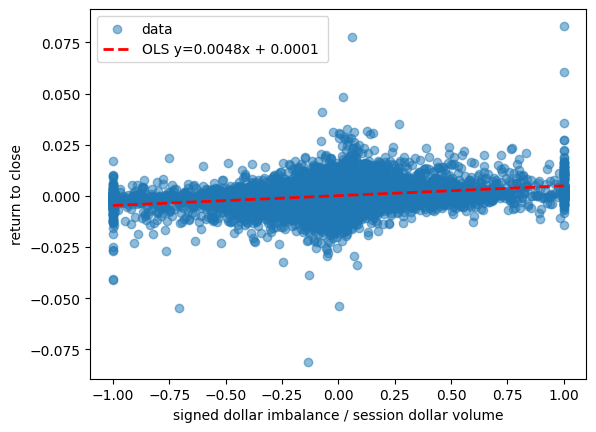

In [75]:
xs = np.linspace(np.min(X[:, 1]), np.max(X[:, 1])).clip()
plt.scatter(X[:, 1], y, alpha=0.5, label="data")
plt.plot(xs, res.params[1] * xs + res.params[0], label=f'OLS y={res.params[1]:,.4f}x + {res.params[0]:,.4f} ', color='red', linestyle='--', linewidth=2)
plt.xlabel("signed dollar imbalance / session dollar volume")
plt.ylabel("return to close")
plt.legend()
plt.show()

In [63]:
np.max(xs)

np.float64(1.0)

#### Quick Backtest

In [28]:
CAP_PER_SYMBOL = 2_500
COMMISSION = 0.0035
backtest = (
    data
    .with_columns(
        pl.when(pl.col("dollar_imbalance") > 500_000).then(True).otherwise(False).alias("tradable"),
    )
    .with_columns(
        ((pl.col("auction_price") - pl.col("last_traded_price")) / pl.col("last_traded_price")).alias("return"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            * pl.col("tradable") * (CAP_PER_SYMBOL // pl.col("last_traded_price"))
        ).alias("traded_qty"),
    )
    .with_columns(
        (pl.col("tradable") * pl.col("traded_qty") * pl.col("last_traded_price") * pl.col("return")).alias("gross_pnl"),
        (pl.col("tradable") * pl.col("traded_qty").abs() * (COMMISSION + pl.col("last_traded_spread")/2)).alias("cost"),
        (pl.col("traded_qty") * pl.col("last_traded_price")).alias("trade_value")
    )
    .with_columns(
        (pl.col("gross_pnl") - pl.col("cost")).alias("net_pnl")
    )

)
backtest.filter(pl.col("tradable") == True)

date,symbol,side,last_traded_price,last_traded_spread,auction_price,auction_dollars,dollar_imbalance,qty_signal,tradable,return,traded_qty,gross_pnl,cost,trade_value,net_pnl
date,cat,str,f64,f64,f64,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64
2026-04-30,"""AAOI""","""A""",165.64,0.12,164.36,1.4868e8,7.4316e7,-0.276891,true,-0.007728,-15.0,19.2,0.9525,-2484.6,18.2475
2026-04-30,"""AAPL""","""B""",274.27,0.02,271.35,6.4765e9,1.8923e9,0.981535,true,-0.010646,9.0,-26.28,0.1215,2468.43,-26.4015
2026-04-30,"""ABNB""","""A""",140.81,0.04,140.36,9.4891e7,1.1539e6,-0.022845,true,-0.003196,-17.0,7.65,0.3995,-2393.77,7.2505
2026-04-30,"""ABVX""","""B""",116.33,0.31,117.38,3.5146e6,1.0564e6,0.05672,true,0.009026,21.0,22.05,3.3285,2442.93,18.7215
2026-04-30,"""ACAD""","""B""",22.555,0.01,22.45,7.0908e6,1.6901e6,0.356952,true,-0.004655,110.0,-11.55,0.935,2481.05,-12.485
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-05-29,"""ZION""","""B""",62.2,0.01,62.45,2.2129e7,5.096357e6,0.25527,true,0.004019,40.0,10.0,0.34,2488.0,9.66
2026-05-29,"""ZLAB""","""A""",17.695,0.02,17.69,1.7572e6,685008.84,-0.245537,true,-0.000283,-141.0,0.705,1.9035,-2494.995,-1.1985
2026-05-29,"""ZM""","""A""",101.69,0.02,101.59,1.7084e8,9.1575e6,-0.145848,true,-0.000983,-24.0,2.4,0.324,-2440.56,2.076


In [29]:
N_days = backtest["date"].n_unique()
stat_backtest = backtest.filter(pl.col("tradable") == True, pl.col("traded_qty") != 0)
total_capital = stat_backtest.group_by("date").agg(pl.col("trade_value").abs().sum()).max()['trade_value'].item()


daily_returns = stat_backtest.group_by("date").agg(pl.col("net_pnl").sum() / pl.col("trade_value").abs().sum()).rename({"net_pnl":"return"})
cum_return = daily_returns.select((1+pl.col('return')).cum_prod()).tail(1).item()-1
daily_avg_return = daily_returns["return"].mean()
daily_std_return = daily_returns["return"].std()

n_trades = len(stat_backtest)
n_profitable_trades = len(stat_backtest.filter(pl.col("net_pnl") > 0))

print(f"Total Invested Capital: ${total_capital:,.2f}")
print(f"Total Gross PNL: ${stat_backtest["gross_pnl"].sum():,.2f}")
print(f"Total Trading Costs PNL: ${stat_backtest["cost"].sum():,.2f}")
print(f"Total Net PNL: ${stat_backtest["net_pnl"].sum():,.2f}")
print(f"Total Return: {cum_return:,.4%}")
print(f"Annualized Return: {(1 + daily_avg_return)**252 - 1:,.2%}")
print(f"Sharpe (Annualized): {daily_avg_return / daily_std_return * 252**0.5:,.2f}")
print()
print(f"Per Trade Average Return (bps): {(stat_backtest['net_pnl'] / stat_backtest['trade_value'].abs()).mean() * 1e4:,.2f}")
print(f"Per Trade Hit Rate: {n_profitable_trades / n_trades:,.2%}")

Total Invested Capital: $2,244,039.85
Total Gross PNL: $44,018.66
Total Trading Costs PNL: $18,897.90
Total Net PNL: $25,120.76
Total Return: 1.6181%
Annualized Return: 21.25%
Sharpe (Annualized): 23.75

Per Trade Average Return (bps): 8.10
Per Trade Hit Rate: 55.56%


In [31]:
print(f"Minimum Capital: {backtest.filter(pl.col("tradable")==True).group_by("date").agg(pl.col("last_traded_price").sum())['last_traded_price'].max():,.2f}")
print(f"N Symbols: {backtest.filter(pl.col("tradable")==True)['symbol'].n_unique()}")

Minimum Capital: 102,670.49
N Symbols: 1319
